<a href="https://colab.research.google.com/github/2470024/data-science-portfolio/blob/main/%E5%8F%82%E8%80%83%EF%BC%89%E9%9C%80%E8%A6%81%E4%BA%88%E6%B8%AC_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pwd

/content


In [ ]:
#データを読み込む

import pandas as pd
import glob

# Get a list of all CSV files in the /content/ directory
csv_files = glob.glob('/content/*.csv')

# Iterate through each file and display the first 5 rows
for file_path in csv_files:
    print(f"\n--- {file_path} ---")
    try:
        df = pd.read_csv(file_path)
        print(df.head().to_markdown(index=False))
    except Exception as e:
        print(f"Error reading {file_path}: {e}")


--- /content/category_names.csv ---
|   商品カテゴリID | 商品カテゴリ名     |
|-----------------:|:-------------------|
|              100 | 映画 - DVD         |
|              110 | PCゲーム - 通常版  |
|              120 | 音楽 - その他      |
|              130 | ゲーム - ゲーム機C |
|              140 | 映画 - ブルーレイ  |

--- /content/sales_history.csv ---
| 日付       |   店舗ID |   商品ID |   商品価格 |   売上個数 |
|:-----------|---------:|---------:|-----------:|-----------:|
| 2018-01-01 |        9 |  1000001 |        420 |          1 |
| 2018-01-01 |        6 |  1000001 |        420 |          1 |
| 2018-01-01 |       10 |  1000001 |        420 |          1 |
| 2018-01-01 |        0 |  1000017 |        250 |          1 |
| 2018-01-01 |        1 |  1000017 |        250 |          1 |

--- /content/item_categories.csv ---
|   商品ID |   商品カテゴリID |
|---------:|-----------------:|
|    1e+06 |              100 |
|    1e+06 |              100 |
|    1e+06 |              100 |
|    1e+06 |              100 |
|    1e+06 |            

In [ ]:
#データフレームにする

import pandas as pd

sales_history_df = pd.read_csv('/content/sales_history.csv')
print('sales_history_df:')
display(sales_history_df.head())

sales_history_df:


,日付,店舗ID,商品ID,商品価格,売上個数
0,2018-01-01,9,1000001,420,1.0
1,2018-01-01,6,1000001,420,1.0
2,2018-01-01,10,1000001,420,1.0
3,2018-01-01,0,1000017,250,1.0
4,2018-01-01,1,1000017,250,1.0


In [ ]:
#データフレームにする

item_categories_df = pd.read_csv('/content/item_categories.csv')
print('item_categories_df:')
display(item_categories_df.head())

item_categories_df:


,商品ID,商品カテゴリID
0,1000001,100
1,1000002,100
2,1000003,100
3,1000004,100
4,1000005,100


In [ ]:
#データフレームにする

category_names_df = pd.read_csv('/content/category_names.csv')
print('category_names_df:')
display(category_names_df.head())

category_names_df:


,商品カテゴリID,商品カテゴリ名
0,100,映画 - DVD
1,110,PCゲーム - 通常版
2,120,音楽 - その他
3,130,ゲーム - ゲーム機C
4,140,映画 - ブルーレイ


In [ ]:
#商品カテゴリ情報をマージする

# Merge sales_history_df with item_categories_df on '商品ID'
sales_history_merged_df = pd.merge(sales_history_df, item_categories_df, on='商品ID', how='left')

# Merge the result with category_names_df on '商品カテゴリID'
final_merged_df = pd.merge(sales_history_merged_df, category_names_df, on='商品カテゴリID', how='left')

print('final_merged_df:')
display(final_merged_df.head())

final_merged_df:


,日付,店舗ID,商品ID,商品価格,売上個数,商品カテゴリID,商品カテゴリ名
0,2018-01-01,9,1000001,420,1.0,100,映画 - DVD
1,2018-01-01,6,1000001,420,1.0,100,映画 - DVD
2,2018-01-01,10,1000001,420,1.0,100,映画 - DVD
3,2018-01-01,0,1000017,250,1.0,100,映画 - DVD
4,2018-01-01,1,1000017,250,1.0,100,映画 - DVD


In [ ]:
#商品を一つ取り出してみる

# Filter for 商品ID=1000001 (assuming 10000001 was a typo)
product_id_to_plot = 1000001
selected_product_df = final_merged_df[final_merged_df['商品ID'] == product_id_to_plot].copy()

print(f"Data for 商品ID={product_id_to_plot}:")
display(selected_product_df.head())

Data for 商品ID=1000001:


,日付,店舗ID,商品ID,商品価格,売上個数,商品カテゴリID,商品カテゴリ名
0,2018-01-01,9,1000001,420,1.0,100,映画 - DVD
1,2018-01-01,6,1000001,420,1.0,100,映画 - DVD
2,2018-01-01,10,1000001,420,1.0,100,映画 - DVD
864,2018-01-02,10,1000001,420,2.0,100,映画 - DVD
865,2018-01-02,9,1000001,420,1.0,100,映画 - DVD


Daily sales for 商品ID=1000001:


,日付,売上個数
0,2018-01-01,3.0
1,2018-01-02,8.0
2,2018-01-03,4.0
3,2018-01-04,2.0
4,2018-01-05,1.0


/tmp/ipython-input-1144848282.py:21: UserWarning: Glyph 26085 (\N{CJK UNIFIED IDEOGRAPH-65E5}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-1144848282.py:21: UserWarning: Glyph 20184 (\N{CJK UNIFIED IDEOGRAPH-4ED8}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-1144848282.py:21: UserWarning: Glyph 22770 (\N{CJK UNIFIED IDEOGRAPH-58F2}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-1144848282.py:21: UserWarning: Glyph 19978 (\N{CJK UNIFIED IDEOGRAPH-4E0A}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-1144848282.py:21: UserWarning: Glyph 20491 (\N{CJK UNIFIED IDEOGRAPH-500B}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-1144848282.py:21: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-1144848282.py:21: UserWarning: Glyph 21830 (\N{CJK UNIFIED IDEOGRAPH-5546}) missi

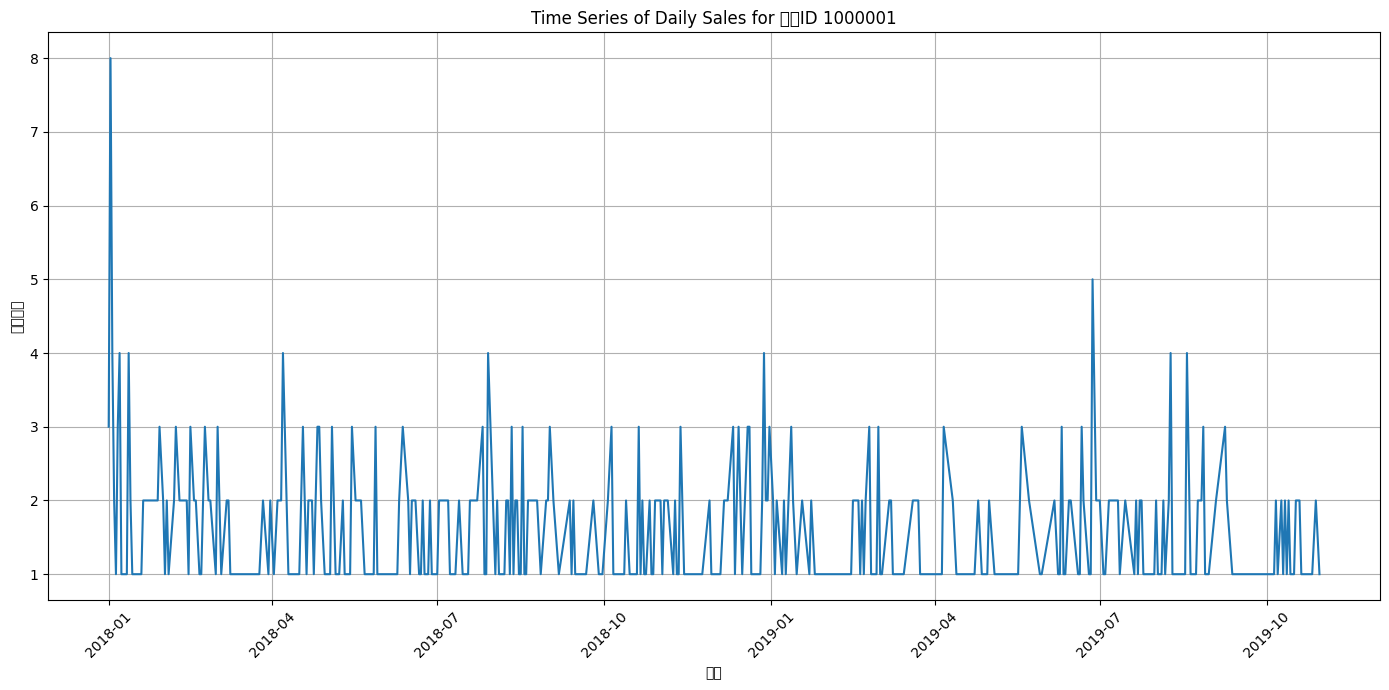

In [ ]:
#商品を一つ取り出してグラフを書いてみる

import matplotlib.pyplot as plt
import seaborn as sns

# Convert '日付' to datetime objects for proper time-series plotting
selected_product_df['日付'] = pd.to_datetime(selected_product_df['日付'])

# Group by date and sum '売上個数' to get daily sales for the selected product
daily_sales_selected_product = selected_product_df.groupby('日付')['売上個数'].sum().reset_index()

print(f"Daily sales for 商品ID={product_id_to_plot}:")
display(daily_sales_selected_product.head())

# Plot the time series
plt.figure(figsize=(14, 7))
sns.lineplot(x='日付', y='売上個数', data=daily_sales_selected_product)
plt.title(f'Time Series of Daily Sales for 商品ID {product_id_to_plot}')
plt.xlabel('日付')
plt.ylabel('売上個数')
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
#ドロップダウンで商品IDが選べるようにしてみる　→　失敗

import ipywidgets as widgets
from IPython.display import display, clear_output
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.font_manager as fm
import matplotlib as mpl

# Install a Japanese font (e.g., IPAexGothic) to display Japanese characters
# This command needs to run in a separate cell if it hasn't been run before
# !apt-get -y install fonts-ipaexgothic
# This code will be added as a separate cell for installation

# Configure matplotlib to use the installed font
# It's important to reload font manager or clear cache after installation

# Ensure '日付' is in datetime format in final_merged_df
final_merged_df['日付'] = pd.to_datetime(final_merged_df['日付'])

# Get all unique product IDs from the merged dataframe
unique_product_ids = final_merged_df['商品ID'].unique()
unique_product_ids.sort() # Sort for better dropdown order

# Create a dropdown widget
product_id_dropdown = widgets.Dropdown(
    options=unique_product_ids,
    value=unique_product_ids[0] if len(unique_product_ids) > 0 else None, # Set initial value
    description='商品ID:',
    disabled=False,
)

def plot_sales_time_series(product_id_to_plot):
    clear_output(wait=True)
    # Removed display(product_id_dropdown) from here to prevent duplication

    if product_id_to_plot is None:
        print("No product selected.")
        return

    # Filter data for the selected product ID
    selected_product_df = final_merged_df[final_merged_df['商品ID'] == product_id_to_plot].copy()

    if selected_product_df.empty:
        print(f"No data available for 商品ID {product_id_to_plot}")
        return

    # Group by date and sum '売上個数' to get daily sales
    daily_sales_selected_product = selected_product_df.groupby('日付')['売上個数'].sum().reset_index()

    # Plot the time series
    plt.figure(figsize=(14, 7))
    sns.lineplot(x='日付', y='売上個数', data=daily_sales_selected_product)
    plt.title(f'Time Series of Daily Sales for 商品ID {product_id_to_plot}')
    plt.xlabel('日付')
    plt.ylabel('売上個数')
    plt.grid(True)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# Link the dropdown to the plotting function and display its output
output = widgets.interactive_output(plot_sales_time_series, {'product_id_to_plot': product_id_dropdown})

# Display the dropdown and the output widget
display(product_id_dropdown, output)

Dropdown(description='商品ID:', options=(np.int64(1000001), np.int64(1000002), np.int64(1000003), np.int64(10000…

Output()

In [ ]:
#文字化けするのでjapanese matplotlibをインストール

# Install japanize-matplotlib for Japanese font support and Matplotlib configuration
!pip install japanize-matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 37.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for japanize-matplotlib: filename=japanize_matplotlib-1.1.3-py3-none-any.whl size=4120257 sha256=dcbd1f83dd1867963a35d1eb5a4c4aa5cc11670803b6fe55f40070630caaa8a2
  Stored in directory: /root/.cache/pip/wheels/c1/f7/9b/418f19a7b9340fc16e071e89efc379aca68d40238b258df53d
Successfully built japanize-matplotlib


In [ ]:
#japanese matplotlibの設定？

import japanize_matplotlib # This line automatically configures matplotlib with a Japanese font
import matplotlib.pyplot as plt

# japanize_matplotlib should have handled the font configuration.
# We can print the font family to confirm if needed.
print(f"Matplotlib font set to: {plt.rcParams['font.family']}")
plt.rcParams['axes.unicode_minus'] = False # To display minus sign correctly

print("Matplotlib font configuration updated. Please re-run the interactive plot cell to see changes.")

Matplotlib font set to: ['IPAexGothic']
Matplotlib font configuration updated. Please re-run the interactive plot cell to see changes.


In [ ]:
#商品IDをプルダウンで選んで時系列グラフを書く　→いくつか見ると、発売日近辺はよく売れることが分かったり

import ipywidgets as widgets
from IPython.display import display, clear_output
import matplotlib.pyplot as plt
import seaborn as sns
import japanize_matplotlib # Ensure Japanese font support is active

# Ensure '日付' is in datetime format in final_merged_df
final_merged_df['日付'] = pd.to_datetime(final_merged_df['日付'])

# Get all unique product IDs from the merged dataframe
unique_product_ids = final_merged_df['商品ID'].unique()
unique_product_ids.sort() # Sort for better dropdown order

# Create a dropdown widget
product_id_dropdown = widgets.Dropdown(
    options=unique_product_ids,
    value=unique_product_ids[0] if len(unique_product_ids) > 0 else None, # Set initial value
    description='商品ID:',
    disabled=False,
)

def plot_sales_time_series(product_id_to_plot):
    clear_output(wait=True)

    if product_id_to_plot is None:
        print("No product selected.")
        return

    # Filter data for the selected product ID
    selected_product_df = final_merged_df[final_merged_df['商品ID'] == product_id_to_plot].copy()

    if selected_product_df.empty:
        print(f"No data available for 商品ID {product_id_to_plot}")
        return

    # Group by date and sum '売上個数' to get daily sales
    daily_sales_selected_product = selected_product_df.groupby('日付')['売上個数'].sum().reset_index()

    # Plot the time series
    plt.figure(figsize=(14, 7))
    sns.lineplot(x='日付', y='売上個数', data=daily_sales_selected_product)
    plt.title(f'商品ID {product_id_to_plot} の日別売上個数の時系列推移')
    plt.xlabel('日付')
    plt.ylabel('売上個数')
    plt.grid(True)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# Link the dropdown to the plotting function and display its output
output = widgets.interactive_output(plot_sales_time_series, {'product_id_to_plot': product_id_dropdown})

# Display the dropdown and the output widget
display(product_id_dropdown, output)

Dropdown(description='商品ID:', options=(np.int64(1000001), np.int64(1000002), np.int64(1000003), np.int64(10000…

Output()

In [ ]:
#売上個数が少なすぎる商品を見ても仕方ないので、日あたり平均売上個数を計算

# Ensure '日付' is in datetime format
final_merged_df['日付'] = pd.to_datetime(final_merged_df['日付'])

# Group by 商品ID and 日付 to get daily sales for each product
daily_sales_by_product = final_merged_df.groupby(['商品ID', '日付'])['売上個数'].sum().reset_index()

# Count the number of unique days each product has data for
product_data_counts = daily_sales_by_product.groupby('商品ID')['日付'].nunique().reset_index()
product_data_counts.rename(columns={'日付': 'データ数'}, inplace=True)

# Filter for products with at least 100 days of data
products_with_sufficient_data = product_data_counts[product_data_counts['データ数'] >= 100]['商品ID']

# Filter the daily sales data for these products
filtered_daily_sales = daily_sales_by_product[daily_sales_by_product['商品ID'].isin(products_with_sufficient_data)]

# Calculate the average daily sales for the filtered products
average_daily_sales = filtered_daily_sales.groupby('商品ID')['売上個数'].mean().reset_index()
average_daily_sales.rename(columns={'売上個数': '日当たり平均売上個数'}, inplace=True)

print("Average daily sales for products with at least 100 days of data:")
display(average_daily_sales.head())

Average daily sales for products with at least 100 days of data:


,商品ID,日当たり平均売上個数
0,1000001,1.576142
1,1000002,1.297414
2,1000003,1.090909
3,1000004,1.135714
4,1000005,1.319853


In [ ]:
#平均売上個数トップ２０

# Merge with item_categories_df to get 商品カテゴリID
top_products_with_categories = pd.merge(average_daily_sales, item_categories_df, on='商品ID', how='left')

# Merge with category_names_df to get 商品カテゴリ名
top_products_with_categories = pd.merge(top_products_with_categories, category_names_df, on='商品カテゴリID', how='left')

# Drop duplicate category information that might arise from item_categories having multiple categories per item
top_products_with_categories.drop_duplicates(subset=['商品ID', '日当たり平均売上個数'], inplace=True)

# Sort by average daily sales in descending order and get the top 20
top_20_products = top_products_with_categories.sort_values(by='日当たり平均売上個数', ascending=False).head(20)

print("Top 20 Products by Average Daily Sales (with category information):")
display(top_20_products)

Top 20 Products by Average Daily Sales (with category information):


,商品ID,日当たり平均売上個数,商品カテゴリID,商品カテゴリ名
548,1100375,23.743869,110,PCゲーム - 通常版
1120,1300289,17.336538,130,ゲーム - ゲーム機C
1098,1300239,16.727092,130,ゲーム - ゲーム機C
1146,1300351,16.574803,130,ゲーム - ゲーム機C
559,1100388,13.807263,110,PCゲーム - 通常版
578,1100423,13.730769,110,PCゲーム - 通常版
279,1001878,12.857143,100,映画 - DVD
365,1002239,12.474453,100,映画 - DVD
1537,1900090,12.449115,190,PCソフト - PCソフト
519,1100304,12.349353,110,PCゲーム - 通常版


Daily sales for 商品ID=1001878 from 2018-07-01 to 2018-08-31:


,日付,売上個数,曜日,表示日付
0,2018-07-01,9.0,日,07/01 (日)
1,2018-07-02,7.0,月,07/02 (月)
2,2018-07-03,6.0,火,07/03 (火)
3,2018-07-04,6.0,水,07/04 (水)
4,2018-07-05,7.0,木,07/05 (木)


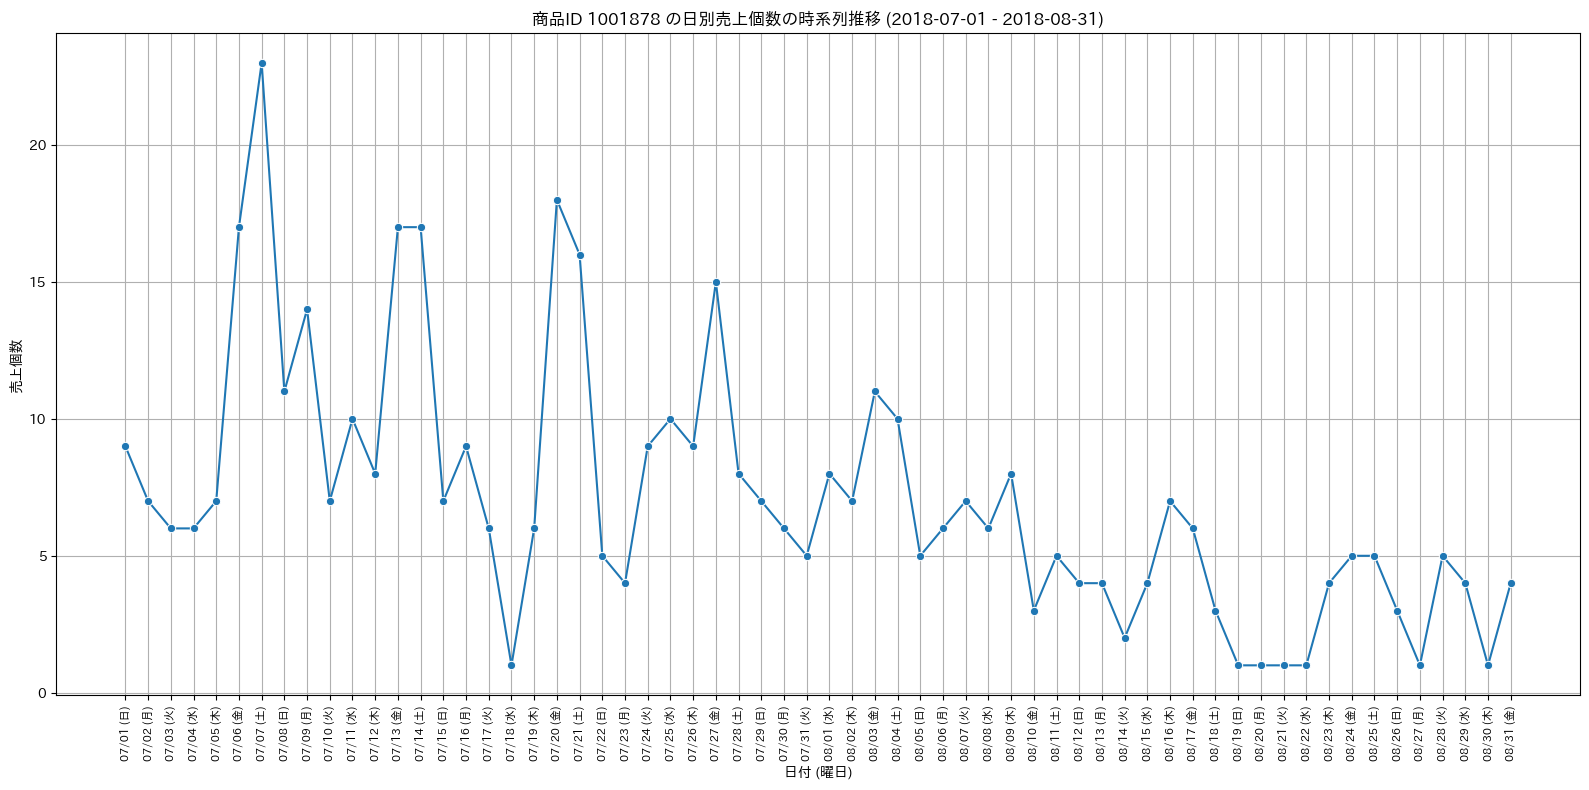

In [ ]:
#売上規模が大きい1001878に絞ってグラフ描画　期間指定　→周期性あり

import matplotlib.pyplot as plt
import seaborn as sns
import japanize_matplotlib # Ensure Japanese font support is active

# Define the specific product ID and date range
product_id_to_plot_specific = 1001878
start_date = '2018-07-01'
end_date = '2018-08-31'

# Ensure '日付' is in datetime format
final_merged_df['日付'] = pd.to_datetime(final_merged_df['日付'])

# Filter for the specific product ID
specific_product_df = final_merged_df[final_merged_df['商品ID'] == product_id_to_plot_specific].copy()

# Filter for the specified date range
specific_product_df = specific_product_df[
    (specific_product_df['日付'] >= start_date) &
    (specific_product_df['日付'] <= end_date)
].copy()

if specific_product_df.empty:
    print(f"No data available for 商品ID {product_id_to_plot_specific} between {start_date} and {end_date}")
else:
    # Group by date and sum '売上個数' to get daily sales
    daily_sales_specific_product = specific_product_df.groupby('日付')['売上個数'].sum().reset_index()

    # Manually add day of the week for better visualization, avoiding locale issues
    japanese_weekdays = ['月', '火', '水', '木', '金', '土', '日']
    daily_sales_specific_product['曜日'] = pd.Categorical(daily_sales_specific_product['日付'].dt.weekday.map(lambda x: japanese_weekdays[x]), categories=japanese_weekdays, ordered=True)
    daily_sales_specific_product['表示日付'] = daily_sales_specific_product['日付'].dt.strftime('%m/%d (') + daily_sales_specific_product['曜日'].astype(str) + ')'

    print(f"Daily sales for 商品ID={product_id_to_plot_specific} from {start_date} to {end_date}:")
    display(daily_sales_specific_product.head())

    # Plot the time series
    plt.figure(figsize=(16, 8))
    sns.lineplot(x='表示日付', y='売上個数', data=daily_sales_specific_product, marker='o')
    plt.title(f'商品ID {product_id_to_plot_specific} の日別売上個数の時系列推移 ({start_date} - {end_date})')
    plt.xlabel('日付 (曜日)')
    plt.ylabel('売上個数')
    plt.grid(True)
    plt.xticks(rotation=90, fontsize=8) # Rotate labels for better readability if many dates
    plt.tight_layout()
    plt.show()

In [ ]:
# Filter final_merged_df for 商品ID=1001878
product_1001878_df = final_merged_df[final_merged_df['商品ID'] == 1001878].copy()

print("DataFrame for 商品ID 1001878 (all periods):")
display(product_1001878_df.head())

DataFrame for 商品ID 1001878 (all periods):


,日付,店舗ID,商品ID,商品価格,売上個数,商品カテゴリID,商品カテゴリ名
264324,2018-05-18,8,1001878,680,1.0,100,映画 - DVD
264325,2018-05-18,9,1001878,680,6.0,100,映画 - DVD
264326,2018-05-18,11,1001878,680,1.0,100,映画 - DVD
264327,2018-05-18,12,1001878,680,1.0,100,映画 - DVD
264328,2018-05-18,10,1001878,680,6.0,100,映画 - DVD


In [ ]:
#Prophetでモデルを作ってみるのでインストール

# First, install prophet if it's not already installed
!pip install prophet

Daily sales for 商品ID=3200004:


,日付,売上個数
0,2018-01-01,3.0
1,2018-01-02,10.0
2,2018-01-03,14.0
3,2018-01-04,16.0
4,2018-01-05,8.0


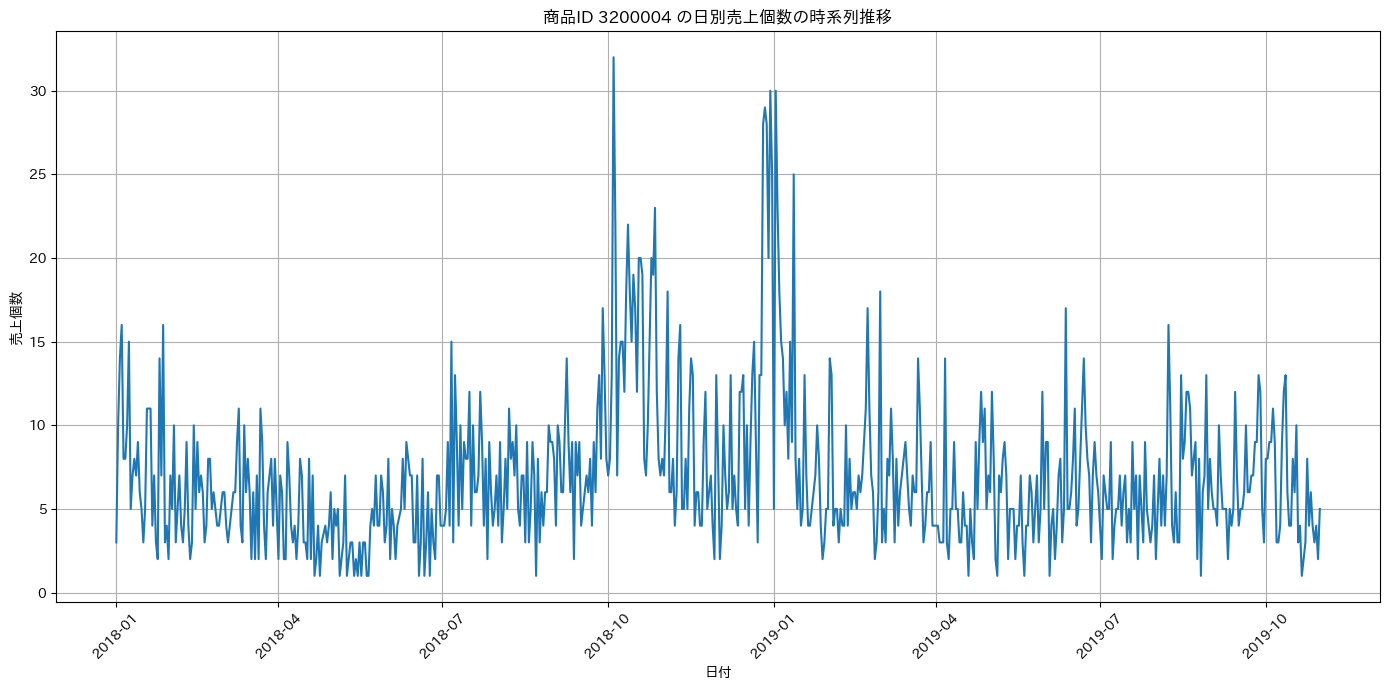

In [ ]:
#データ量が多い3200004をサンプルにする。まずは時系列グラフ描画

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import japanize_matplotlib # Ensure Japanese font support is active

product_id_to_plot = 3200004

# Ensure '日付' is in datetime format
final_merged_df['日付'] = pd.to_datetime(final_merged_df['日付'])

# Filter data for the selected product ID
selected_product_df = final_merged_df[final_merged_df['商品ID'] == product_id_to_plot].copy()

if selected_product_df.empty:
    print(f"No data available for 商品ID {product_id_to_plot}")
else:
    # Group by date and sum '売上個数' to get daily sales
    daily_sales_selected_product = selected_product_df.groupby('日付')['売上個数'].sum().reset_index()

    print(f"Daily sales for 商品ID={product_id_to_plot}:")
    display(daily_sales_selected_product.head())

    # Plot the time series
    plt.figure(figsize=(14, 7))
    sns.lineplot(x='日付', y='売上個数', data=daily_sales_selected_product)
    plt.title(f'商品ID {product_id_to_plot} の日別売上個数の時系列推移')
    plt.xlabel('日付')
    plt.ylabel('売上個数')
    plt.grid(True)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

Data prepared for Prophet training for 商品ID=3200004 (first 5 rows):


,ds,y
0,2018-01-01,3.0
1,2018-01-02,10.0
2,2018-01-03,14.0
3,2018-01-04,16.0
4,2018-01-05,8.0


Data prepared for Prophet training for 商品ID=3200004 (last 5 rows):


,ds,y
536,2019-06-26,3.0
537,2019-06-27,7.0
538,2019-06-28,9.0
539,2019-06-29,7.0
540,2019-06-30,6.0


Forecast generated (first 5 rows):


,ds,yhat,yhat_lower,yhat_upper
0,2018-01-01,11.729198,7.264756,15.980286
1,2018-01-02,11.793474,7.367436,16.036324
2,2018-01-03,11.998177,7.464932,16.043690
3,2018-01-04,12.786955,8.512855,16.960781
4,2018-01-05,13.341543,9.243261,17.591828


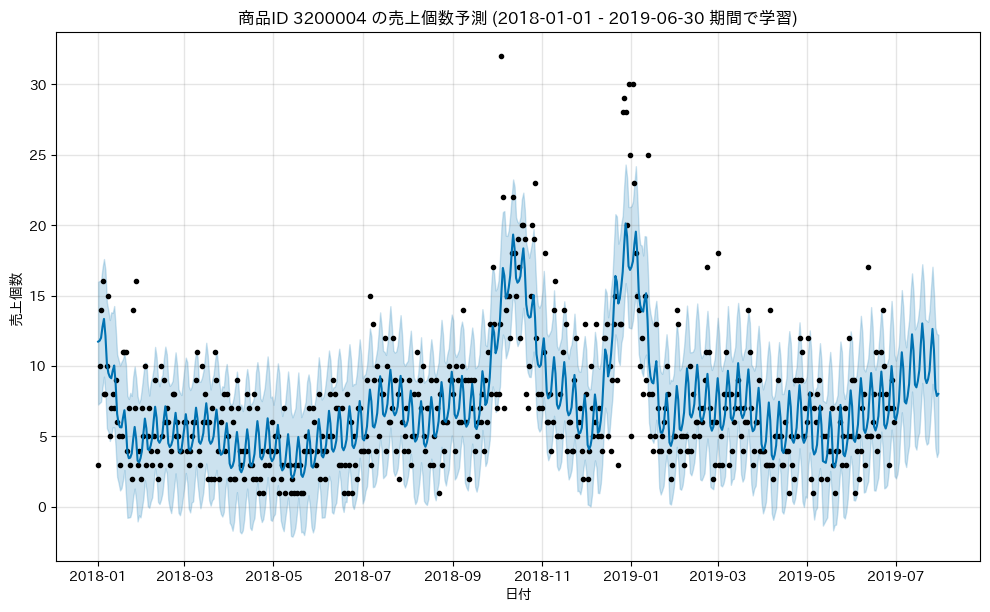

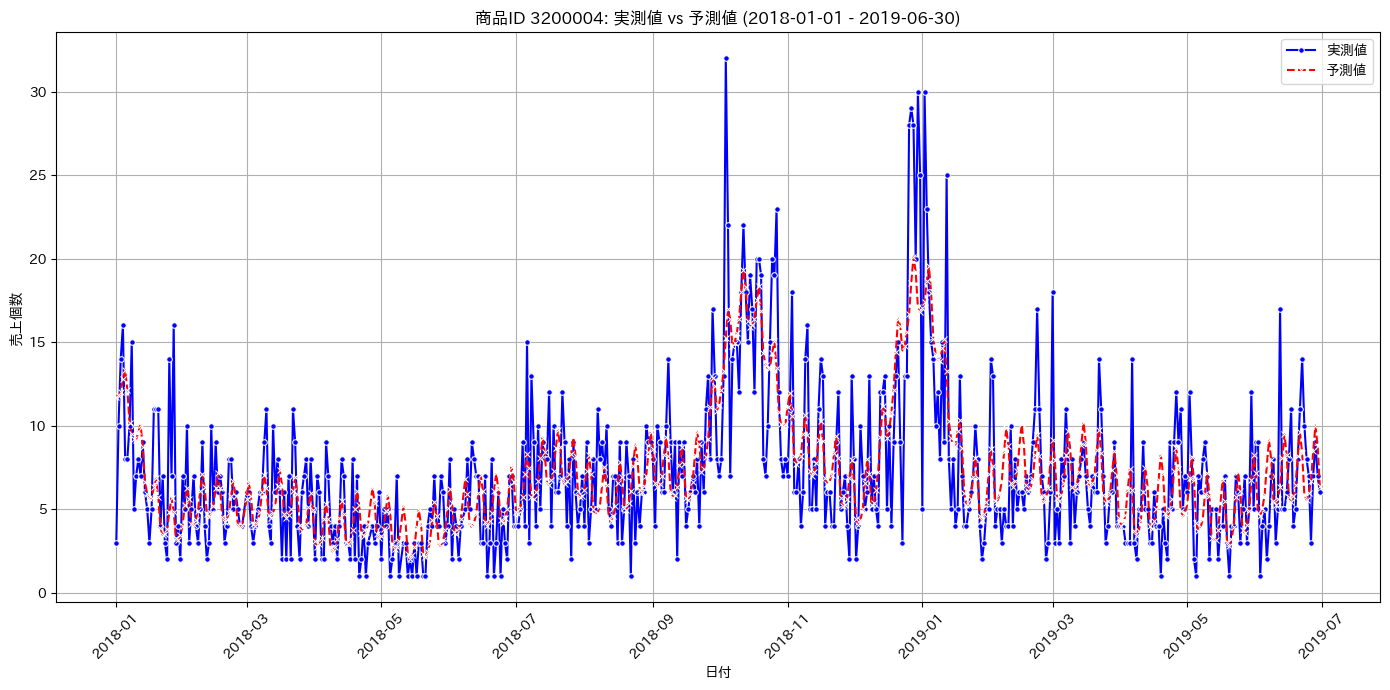

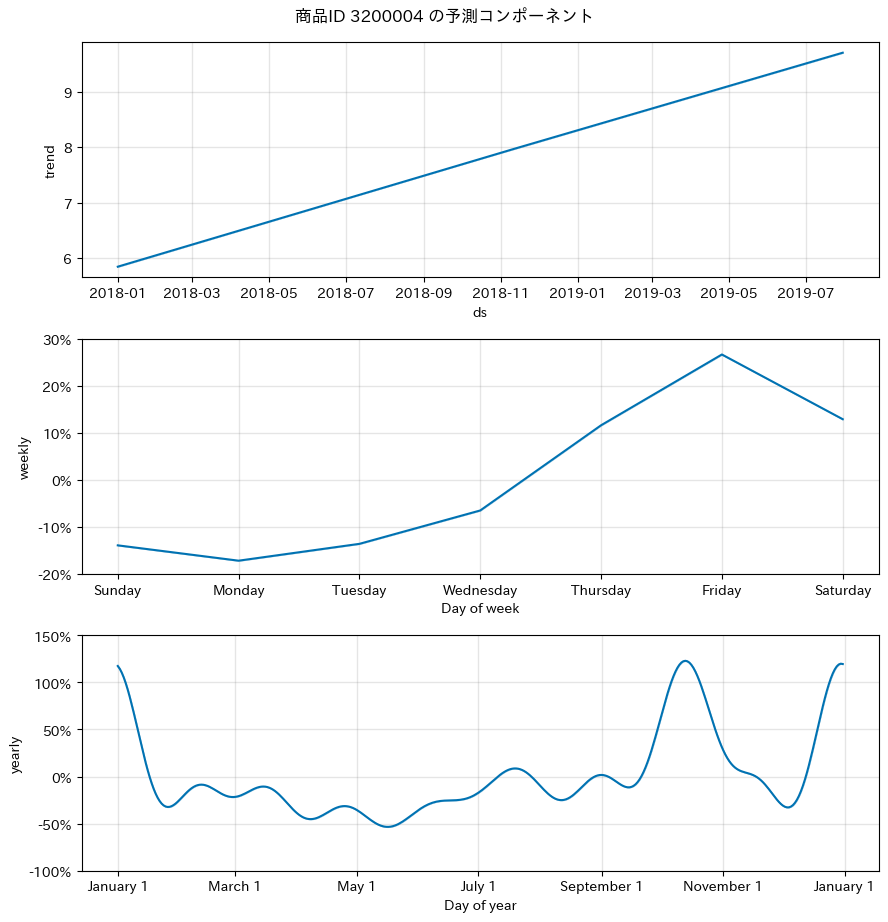

In [ ]:
# 2018年1月～2019年6月の１年半を学習期間として学習

from prophet import Prophet
import pandas as pd
import matplotlib.pyplot as plt
import japanize_matplotlib # Ensure Japanese font support is active
import seaborn as sns

# Define the target product ID and date range for training
product_id_for_prophet = 3200004
start_train_date_new = '2018-01-01'
end_train_date_new = '2019-06-30'

# Ensure '日付' in final_merged_df is datetime
final_merged_df['日付'] = pd.to_datetime(final_merged_df['日付'])

# Filter the data for the specified product ID and training period
prophet_product_df = final_merged_df[
    (final_merged_df['商品ID'] == product_id_for_prophet) &
    (final_merged_df['日付'] >= start_train_date_new) &
    (final_merged_df['日付'] <= end_train_date_new)
].copy()

# Aggregate daily sales for the product
prophet_product_df_daily = prophet_product_df.groupby('日付')['売上個数'].sum().reset_index()

# Prepare the DataFrame for Prophet: 'ds' for datestamp, 'y' for the metric
prophet_df_new = prophet_product_df_daily.rename(columns={'日付': 'ds', '売上個数': 'y'})

if prophet_df_new.empty:
    print(f"No data available for Prophet training for 商品ID={product_id_for_prophet} between {start_train_date_new} and {end_train_date_new}")
else:
    print(f"Data prepared for Prophet training for 商品ID={product_id_for_prophet} (first 5 rows):")
    display(prophet_df_new.head())

    print(f"Data prepared for Prophet training for 商品ID={product_id_for_prophet} (last 5 rows):")
    display(prophet_df_new.tail())

    # Initialize and fit the Prophet model
    model_new = Prophet(
        seasonality_mode='multiplicative',
        yearly_seasonality=True,
        weekly_seasonality=True,
        daily_seasonality=False # Daily seasonality often needs high frequency data to be effective
    )
    model_new.fit(prophet_df_new)

    # Create a DataFrame for future predictions (e.g., for 30 days beyond the training data)
    future_new = model_new.make_future_dataframe(periods=30)

    # Make predictions
    forecast_new = model_new.predict(future_new)

    print("Forecast generated (first 5 rows):")
    display(forecast_new[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].head())

    # Plot the forecast (Prophet's default plot includes actuals as black dots and forecast as blue line)
    fig_new = model_new.plot(forecast_new)
    plt.title(f'商品ID {product_id_for_prophet} の売上個数予測 ({start_train_date_new} - {end_train_date_new} 期間で学習)')
    plt.xlabel('日付')
    plt.ylabel('売上個数')
    plt.show()

    # Plot actuals and predictions as line graphs for the training period
    plt.figure(figsize=(14, 7))

    # Merge actuals with predictions for the training period
    actuals_vs_predictions_new = pd.merge(prophet_df_new, forecast_new[['ds', 'yhat']], on='ds', how='inner')

    sns.lineplot(x='ds', y='y', data=actuals_vs_predictions_new, label='実測値', color='blue', marker='o', markersize=4)
    sns.lineplot(x='ds', y='yhat', data=actuals_vs_predictions_new, label='予測値', color='red', linestyle='--', marker='x', markersize=4)

    plt.title(f'商品ID {product_id_for_prophet}: 実測値 vs 予測値 ({start_train_date_new} - {end_train_date_new})')
    plt.xlabel('日付')
    plt.ylabel('売上個数')
    plt.legend()
    plt.grid(True)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    # Plot components
    fig2_new = model_new.plot_components(forecast_new)
    plt.suptitle(f'商品ID {product_id_for_prophet} の予測コンポーネント', y=1.02) # Add suptitle to avoid overlapping with subplots
    plt.show()

In [ ]:
#2019年7-9月をスコアリング

import pandas as pd

# Define the prediction period
prediction_start_date_q3 = '2019-07-01'
prediction_end_date_q3 = '2019-09-30'

# The model_new was trained up to '2019-06-30' (prophet_df_new['ds'].max())
last_train_date_for_model = prophet_df_new['ds'].max()

# Calculate the number of days from the last training date to the end of the desired prediction period
periods_to_add_for_prediction_q3 = (pd.to_datetime(prediction_end_date_q3) - last_train_date_for_model).days

# Create an extended future DataFrame for predictions
# make_future_dataframe includes the dates in the original data, so periods needs to be from the last original date
extended_future_q3 = model_new.make_future_dataframe(periods=periods_to_add_for_prediction_q3)

# Generate predictions using the model_new
extended_forecast_q3 = model_new.predict(extended_future_q3)

# Filter the forecast to show only the requested period (July 2019 to September 2019)
requested_predictions_q3 = extended_forecast_q3[
    (extended_forecast_q3['ds'] >= prediction_start_date_q3) &
    (extended_forecast_q3['ds'] <= prediction_end_date_q3)
].copy()

print(f"Predictions for 商品ID {product_id_for_prophet} from {prediction_start_date_q3} to {prediction_end_date_q3}:")
display(requested_predictions_q3[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].head())

Predictions for 商品ID 3200004 from 2019-07-01 to 2019-09-30:


,ds,yhat,yhat_lower,yhat_upper
541,2019-07-01,6.177162,2.089267,10.507258
542,2019-07-02,6.656693,2.651661,10.962755
543,2019-07-03,7.482923,2.943168,11.714430
544,2019-07-04,9.369904,5.122456,13.769755
545,2019-07-05,10.975803,6.608714,15.211519


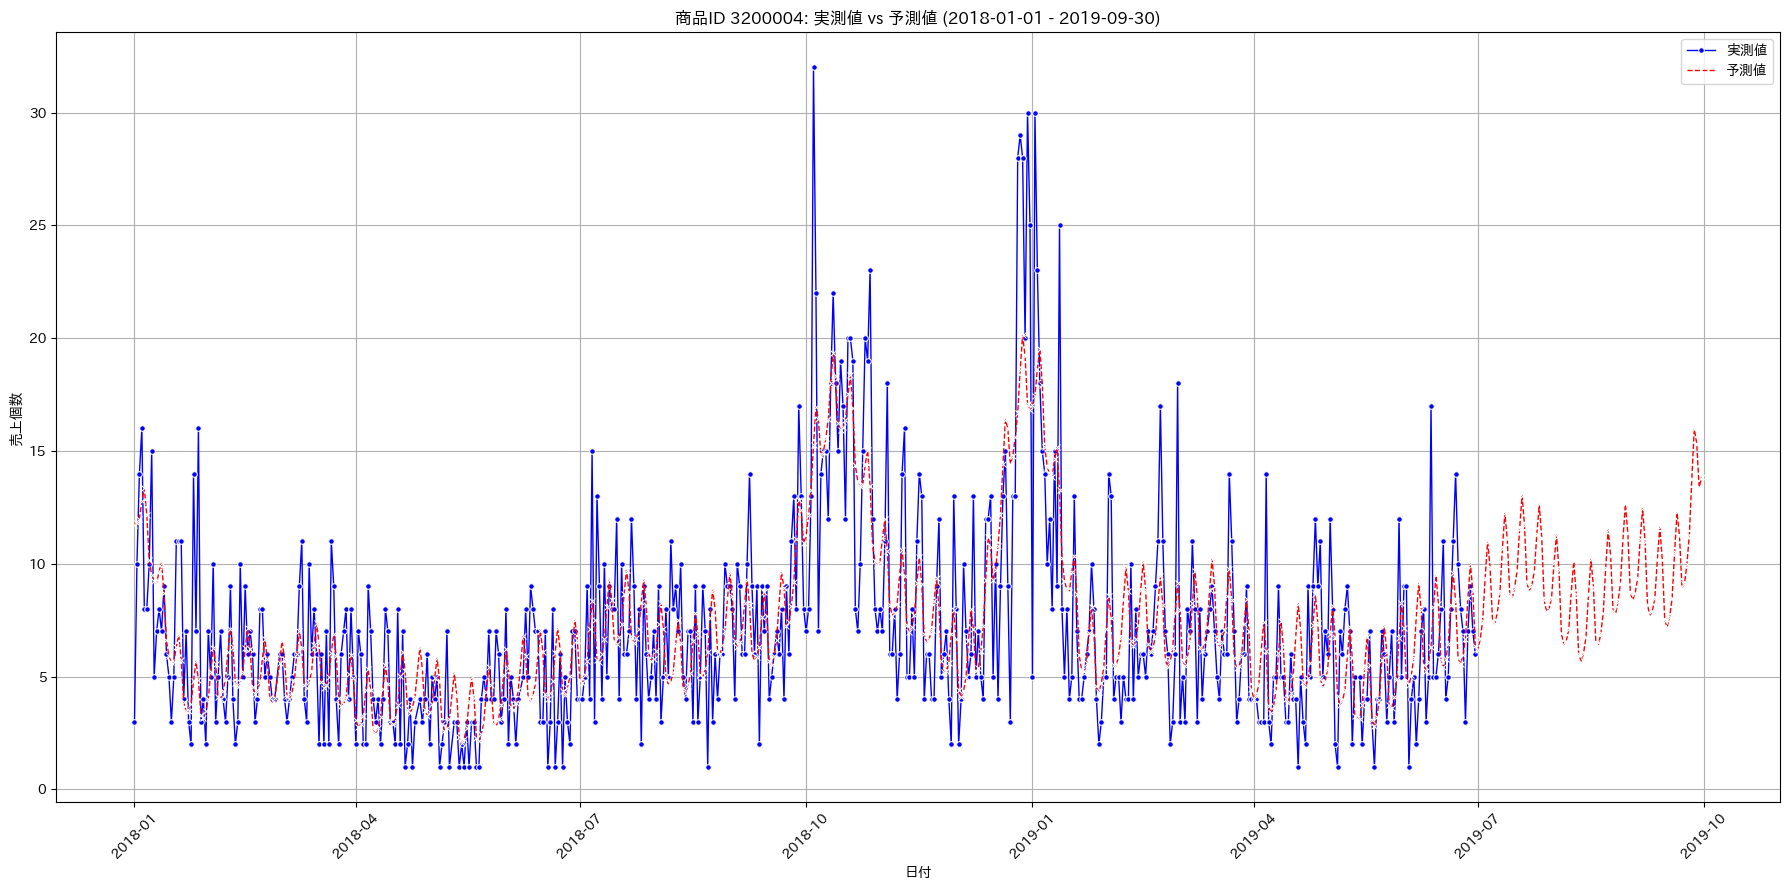

In [ ]:
#予実グラフ描画

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import japanize_matplotlib # Ensure Japanese font support is active

# Define the full plotting period
start_plot_date = prophet_df_new['ds'].min()
end_plot_date = requested_predictions_q3['ds'].max()

# --- Combine all predictions ---
# We need to ensure forecast_new covers up to the end of the training period for proper merging
# extended_forecast_q3 contains all predictions from the start of training to the end of Q3 2019

# Filter extended_forecast_q3 to cover the full plotting range
full_predictions_for_plot = extended_forecast_q3[
    (extended_forecast_q3['ds'] >= start_plot_date) &
    (extended_forecast_q3['ds'] <= end_plot_date)
].copy()

# --- Merge Actuals and Predictions for Plotting ---
# We have actuals in prophet_df_new for the training period (Jan 2018 - Jun 2019)
# We need to merge these actuals with the predictions
combined_plot_df_final = pd.merge(
    prophet_df_new, # Actuals from Jan 2018 to Jun 2019
    full_predictions_for_plot[['ds', 'yhat']],
    on='ds',
    how='outer' # Use outer to include all dates where either actuals or predictions exist
).sort_values('ds').reset_index(drop=True)

# For dates beyond the training period (July 2019 - Sep 2019), 'y' will be NaN in combined_plot_df_final
# We will only plot 'yhat' for these dates, and 'y' for the training period.

# --- Plotting ---
plt.figure(figsize=(18, 9))

# Plot actuals (will only appear for Jan 2018 - Jun 2019)
sns.lineplot(x='ds', y='y', data=combined_plot_df_final, label='実測値', color='blue', marker='o', markersize=4, linewidth=1)

# Plot predictions (will appear for Jan 2018 - Sep 2019)
sns.lineplot(x='ds', y='yhat', data=combined_plot_df_final, label='予測値', color='red', linestyle='--', marker='x', markersize=4, linewidth=1)

plt.title(f'商品ID {product_id_for_prophet}: 実測値 vs 予測値 ({start_plot_date.strftime('%Y-%m-%d')} - {end_plot_date.strftime('%Y-%m-%d')})')
plt.xlabel('日付')
plt.ylabel('売上個数')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

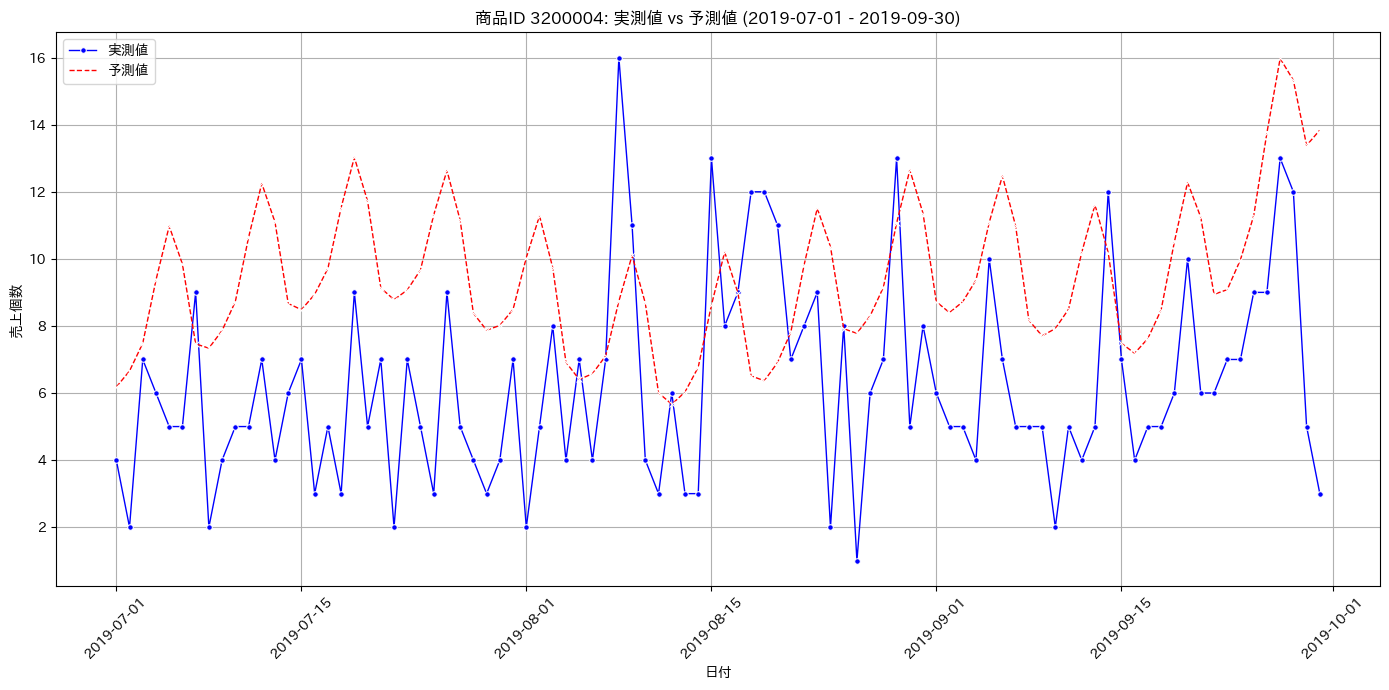

In [ ]:
#2019年7-9月に絞って予実グラフ

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import japanize_matplotlib # Ensure Japanese font support is active

# Define the specific plotting range
plot_start_date_q3 = '2019-07-01'
plot_end_date_q3 = '2019-09-30'

# --- Get Actuals for the Q3 period from final_merged_df ---
# Filter final_merged_df for the specific product and Q3 date range
actuals_q3_df = final_merged_df[
    (final_merged_df['商品ID'] == product_id_for_prophet) &
    (final_merged_df['日付'] >= plot_start_date_q3) &
    (final_merged_df['日付'] <= plot_end_date_q3)
].copy()

# Aggregate daily sales for actuals
actuals_q3_daily = actuals_q3_df.groupby('日付')['売上個数'].sum().reset_index()
actuals_q3_daily.rename(columns={'日付': 'ds', '売上個数': 'y'}, inplace=True)

# Ensure 'ds' in actuals_q3_daily is datetime (it should be if final_merged_df['日付'] was converted)
actuals_q3_daily['ds'] = pd.to_datetime(actuals_q3_daily['ds'])

# --- Merge Actuals with Predictions for the Q3 period ---
# requested_predictions_q3 contains 'ds' and 'yhat' for Q3
# Ensure 'ds' in requested_predictions_q3 is also datetime
requested_predictions_q3['ds'] = pd.to_datetime(requested_predictions_q3['ds'])

# Merge actuals_q3_daily with requested_predictions_q3
merged_q3_plot_df = pd.merge(
    actuals_q3_daily,
    requested_predictions_q3[['ds', 'yhat']],
    on='ds',
    how='outer' # Use outer to include all dates where either actuals or predictions exist
).sort_values('ds').reset_index(drop=True)

# Plotting
plt.figure(figsize=(14, 7))
sns.lineplot(x='ds', y='y', data=merged_q3_plot_df, label='実測値', color='blue', marker='o', markersize=4, linewidth=1)
sns.lineplot(x='ds', y='yhat', data=merged_q3_plot_df, label='予測値', color='red', linestyle='--', marker='x', markersize=4, linewidth=1)

plt.title(f'商品ID {product_id_for_prophet}: 実測値 vs 予測値 ({plot_start_date_q3} - {plot_end_date_q3})')
plt.xlabel('日付')
plt.ylabel('売上個数')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

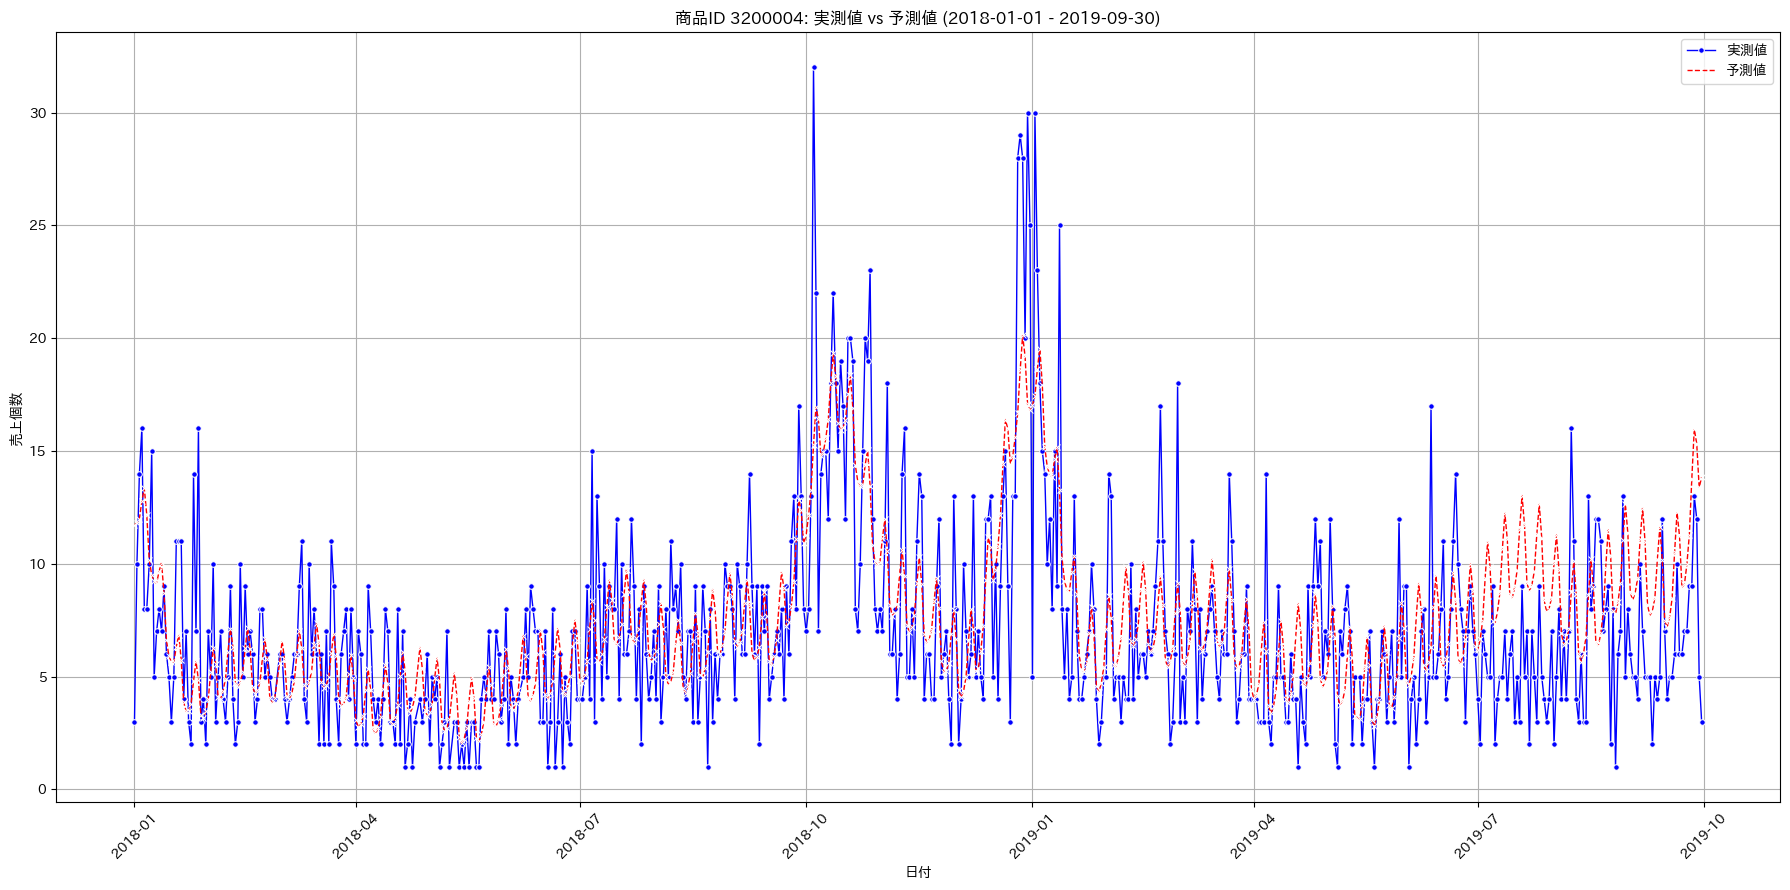

In [ ]:
#全期間の予実グラフ

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import japanize_matplotlib # Ensure Japanese font support is active

# --- Combine all actuals (Jan 2018 - Sep 2019) ---
# prophet_df_new contains actuals from 2018-01-01 to 2019-06-30
# actuals_q3_daily contains actuals from 2019-07-01 to 2019-09-30
all_actuals = pd.concat([prophet_df_new, actuals_q3_daily]).sort_values('ds').reset_index(drop=True)

# --- Filter predictions for the full period (Jan 2018 - Sep 2019) ---
# extended_forecast_q3 contains predictions from 2018-01-01 up to 2019-09-30
start_plot_date = all_actuals['ds'].min()
end_plot_date = all_actuals['ds'].max()

full_predictions_for_plot = extended_forecast_q3[
    (extended_forecast_q3['ds'] >= start_plot_date) &
    (extended_forecast_q3['ds'] <= end_plot_date)
].copy()

# --- Merge Actuals and Predictions for Plotting ---
final_combined_plot_df = pd.merge(
    all_actuals,
    full_predictions_for_plot[['ds', 'yhat']],
    on='ds',
    how='left' # Use left join to keep all actuals and add predictions
).sort_values('ds').reset_index(drop=True)

# For dates where actuals might be missing (e.g., if the model predicted beyond available actuals)
# we can fill 'y' with NaN if not present, which is already done by the left join if 'ds' don't match

# Plotting
plt.figure(figsize=(18, 9))
sns.lineplot(x='ds', y='y', data=final_combined_plot_df, label='実測値', color='blue', marker='o', markersize=4, linewidth=1)
sns.lineplot(x='ds', y='yhat', data=final_combined_plot_df, label='予測値', color='red', linestyle='--', marker='x', markersize=4, linewidth=1)

plt.title(f'商品ID {product_id_for_prophet}: 実測値 vs 予測値 ({start_plot_date.strftime('%Y-%m-%d')} - {end_plot_date.strftime('%Y-%m-%d')})')
plt.xlabel('日付')
plt.ylabel('売上個数')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()